In [1]:
#We are combining three data files into one master dataset to solve the research question

In [2]:
#Research Question: Are property prices in Mexico more influenced by property size or by location?

In [3]:
#import panda as pd for data maniupulation
import pandas as pd


In [4]:
# the path to our first data file
path_1 = "OneDrive/Documents/Excel files/mexico-real-estate-1.csv"

print(f'We will load the data from "{path_1}"')

We will load the data from "OneDrive/Documents/Excel files/mexico-real-estate-1.csv"


In [5]:
# we will load the dataset using the variable 7 check the first five rows of the data
(
    pd.read_csv(path_1)
    .head()
)


,property_type,state,lat,lon,area_m2,price_usd
0,house,Estado de México,19.560181,-99.233528,150.0,"$67,965.56"
1,house,Nuevo León,25.688436,-100.198807,186.0,"$63,223.78"
2,apartment,Guerrero,16.767704,-99.764383,82.0,"$84,298.37"
3,apartment,Guerrero,16.829782,-99.911012,150.0,"$94,308.80"
4,house,Veracruz de Ignacio de la Llave,NaN,NaN,175.0,"$94,835.67"


In [6]:
# Let's check total columns and rows we have
(
    pd.read_csv(path_1)
    .shape
)


(700, 6)

In [7]:
(
    pd.read_csv(path_1)
    .info()
)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 700 entries, 0 to 699
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   property_type  700 non-null    object 
 1   state          700 non-null    object 
 2   lat            583 non-null    float64
 3   lon            583 non-null    float64
 4   area_m2        700 non-null    float64
 5   price_usd      700 non-null    object 
dtypes: float64(3), object(3)
memory usage: 32.9+ KB


In [8]:
(
    pd.read_csv(path_1)
    .dtypes
)

property_type     object
state             object
lat              float64
lon              float64
area_m2          float64
price_usd         object
dtype: object

In [9]:
( # Let's know the number of missing value in each column
    pd.read_csv(path_1)
    .isnull()
    .sum()
)  

property_type      0
state              0
lat              117
lon              117
area_m2            0
price_usd          0
dtype: int64

In [10]:
# Cleaning the first dataset
df1 = (
    pd.read_csv(path_1)
    .dropna() # For dropping the 117 missing values in each columns
        
    .assign(price_usd = lambda x:
            x["price_usd"]    #select the text column
                .str.replace("$", "", regex=False)   # To remove the $ sign
                .str.replace(",", "", regex=False)   # To remove the thousands comma
                .astype(float)  # convert the text to Number
           )
)
print(f'The number of: {df1.shape[0]} rows & {df1.shape[1]} columns')

df1



The number of: 583 rows & 6 columns


,property_type,state,lat,lon,area_m2,price_usd
0,house,Estado de México,19.560181,-99.233528,150.0,67965.56
1,house,Nuevo León,25.688436,-100.198807,186.0,63223.78
2,apartment,Guerrero,16.767704,-99.764383,82.0,84298.37
3,apartment,Guerrero,16.829782,-99.911012,150.0,94308.80
5,house,Yucatán,21.052583,-89.538639,205.0,105191.37
...,...,...,...,...,...,...
693,house,Puebla,19.051815,-98.277669,198.0,115910.26
694,apartment,Distrito Federal,19.309208,-99.171906,70.0,77572.89
696,house,Yucatán,21.050653,-89.558841,334.0,137017.34
697,house,Yucatán,21.343796,-89.262060,130.0,110404.35


In [11]:
# define the path to our data file
path_2 = "OneDrive/Documents/Excel files/mexico-real-estate-2.csv"

In [12]:
# we are loading the second file
(
    pd.read_csv(path_2).head()
)


,property_type,state,lat,lon,area_m2,price_mxn
0,apartment,Nuevo León,25.721081,-100.345581,72.0,1300000.0
1,apartment,Puebla,NaN,NaN,190.0,2500000.0
2,house,Morelos,23.634501,-102.552788,360.0,5300000.0
3,house,Morelos,NaN,NaN,76.0,820000.0
4,house,Puebla,NaN,NaN,200.0,1100000.0


In [13]:
#we can see that path_2 file stores price in Mexican Pesos instead of US dollars
# we need to convert Mexican pesos to US dollars


df2 = (
    pd.read_csv(path_2) #load the dataset

    .assign(price_usd = lambda x: x['price_mxn'].div(19)) # Create "price_usd" column (19 pesos to the dollar in 2014)

    .drop(columns = ["price_mxn"]) # drop the price_mxn column to resembles data_1

    .dropna() # To drop all the missing values
)

print(f'df2 shape: {df2.shape}')

df2.head()

df2 shape: (571, 6)


,property_type,state,lat,lon,area_m2,price_usd
0,apartment,Nuevo León,25.721081,-100.345581,72.0,68421.052632
2,house,Morelos,23.634501,-102.552788,360.0,278947.368421
6,apartment,Estado de México,19.272040,-99.572013,85.0,65789.473684
7,house,San Luis Potosí,22.138882,-100.996510,158.0,111578.947368
8,apartment,Distrito Federal,19.394558,-99.129707,65.0,39904.736842


In [14]:
#Path to our third file
path_3 = "OneDrive/Documents/Excel files/mexico-real-estate-3.csv"

In [15]:
(
    pd.read_csv(path_3).info()
)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 700 entries, 0 to 699
Data columns (total 5 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   property_type            700 non-null    object 
 1   place_with_parent_names  700 non-null    object 
 2   lat-lon                  582 non-null    object 
 3   area_m2                  700 non-null    float64
 4   price_usd                700 non-null    float64
dtypes: float64(2), object(3)
memory usage: 27.5+ KB


In [16]:
(
    pd.read_csv(path_3).head() # load the dataset head
)

,property_type,place_with_parent_names,lat-lon,area_m2,price_usd
0,apartment,|México|Distrito Federal|Gustavo A. Madero|Acu...,"19.52589,-99.151703",71.0,48550.59
1,house,|México|Estado de México|Toluca|Metepec|,"19.2640539,-99.5727534",233.0,168636.73
2,house,|México|Estado de México|Toluca|Toluca de Lerd...,"19.268629,-99.671722",300.0,86932.69
3,house,|México|Morelos|Temixco|Burgos Bugambilias|,NaN,275.0,263432.41
4,apartment,|México|Veracruz de Ignacio de la Llave|Veracruz|,"19.511938,-96.871956",84.0,68508.67


In [17]:
#There is a problem with  place_with_parent_names & lat-lon, we need to seperate each column
#Both problems require string splitting — cutting a text cell apart at a known separator character and extracting the piece(s) we need.

#We first split lat-lon column cause we need it to train our model

(
    pd.read_csv(path_3)
    ['lat-lon'].str.split(",", expand=True) #split the lat-lon column into column[0 & 1]
        .head()
)


,0,1
0,19.52589,-99.151703
1,19.2640539,-99.5727534
2,19.268629,-99.671722
3,NaN,NaN
4,19.511938,-96.871956


In [18]:
(
    pd.read_csv(path_3)
    ["lat-lon"].str.split(",", expand=True)[0] #split the ["lat-lon"] with comma
    .astype(float) # convert string to number
     
    .head()
    
)

0    19.525890
1    19.264054
2    19.268629
3          NaN
4    19.511938
Name: 0, dtype: float64

In [19]:
#Inspect the place_with_parent_names column
(
    pd.read_csv(path_3)
    ["place_with_parent_names"]
    .head()
)

0    |México|Distrito Federal|Gustavo A. Madero|Acu...
1             |México|Estado de México|Toluca|Metepec|
2    |México|Estado de México|Toluca|Toluca de Lerd...
3          |México|Morelos|Temixco|Burgos Bugambilias|
4    |México|Veracruz de Ignacio de la Llave|Veracruz|
Name: place_with_parent_names, dtype: object

In [20]:
#lets split the "place_with_parent_names" column with pipe character

(
    pd.read_csv(path_3)
    ["place_with_parent_names"]
    .str.split("|", expand=True)
    .head()
)


,0,1,2,3,4,5,6
0,,México,Distrito Federal,Gustavo A. Madero,Acueducto de Guadalupe,,None
1,,México,Estado de México,Toluca,Metepec,,None
2,,México,Estado de México,Toluca,Toluca de Lerdo,Ocho Cedros,
3,,México,Morelos,Temixco,Burgos Bugambilias,,None
4,,México,Veracruz de Ignacio de la Llave,Veracruz,,None,None


In [21]:
#lets complete df3 cleaning pipeline
# cleaning process 
df3 = (
    pd.read_csv(path_3)
    # Drop null values from df3
    .dropna()
    # Create "lat" and "lon" columns for df3
    .assign(lat=lambda x: x["lat-lon"]
                .str.split(",", expand=True)[0]           
                .astype(float),
            lon=lambda x: x["lat-lon"]
                .str.split(",", expand=True)[1]           
                .astype(float),
            # Create "state" column for df3
            state=lambda x: x["place_with_parent_names"]
            .str.split("|", expand=True)[2]
           )
    
    # Drop "place_with_parent_names" and "lat-lon" from df3
    .drop(columns=["place_with_parent_names", "lat-lon"])
            
    
)

# Print object type, shape, and head
print("df3 type:", type(df3))
print("df3 shape:", df3.shape)
df3.head()

df3 type: <class 'pandas.core.frame.DataFrame'>
df3 shape: (582, 6)


,property_type,area_m2,price_usd,lat,lon,state
0,apartment,71.0,48550.59,19.525890,-99.151703,Distrito Federal
1,house,233.0,168636.73,19.264054,-99.572753,Estado de México
2,house,300.0,86932.69,19.268629,-99.671722,Estado de México
4,apartment,84.0,68508.67,19.511938,-96.871956,Veracruz de Ignacio de la Llave
5,house,175.0,102763.00,20.689157,-103.366728,Jalisco


In [22]:
#letsCheck if all column sets are identical
columns_match = set(df1) == set(df2) == set(df3)

if columns_match:
    print("✅ All DataFrames have the same columns.")
else:
    print("❌ Column mismatch detected!")
    # Optional: See the difference
    print("df1 vs df2 diff:", set(df1.columns) ^ set(df2.columns))
    print("df2 vs df3 diff:", set(df2.columns) ^ set(df3.columns))

✅ All DataFrames have the same columns.


In [23]:
#lets put all dataframes together using pd.concat

df = pd.concat([df1, df2, df3], ignore_index = True)

# ignore_index=True discards all three original indices and assigns a fresh continuous index (0, 1, 2, ..., N-1) to the combined DataFrame. 

print(f'combined shape: {df.shape}')
df.head()

combined shape: (1736, 6)


,property_type,state,lat,lon,area_m2,price_usd
0,house,Estado de México,19.560181,-99.233528,150.0,67965.56
1,house,Nuevo León,25.688436,-100.198807,186.0,63223.78
2,apartment,Guerrero,16.767704,-99.764383,82.0,84298.37
3,apartment,Guerrero,16.829782,-99.911012,150.0,94308.80
4,house,Yucatán,21.052583,-89.538639,205.0,105191.37


In [24]:
# Save your cleaned combined dataset
df.to_csv("./mexico-real-estate-combined-clean.csv", index = False)

In [25]:
# lets check what does the overall distribution of prices and areas look like

summary = df[["price_usd", "area_m2"]].describe()
summary         

,price_usd,area_m2
count,1736.000000,1736.000000
mean,115331.980800,170.261521
std,65426.173793,80.594539
min,33157.894737,60.000000
25%,65789.473684,101.750000
50%,99262.132105,156.000000
75%,150846.665000,220.000000
max,326733.660000,385.000000


In [26]:
# When mean ≠ median, the distribution is not symmetric. right skewed for both price and area means the mean was higher than the median
# but we could not see the distribution shape. We could not see where the outliers were. 

# .describe() told us the mean price was around $115,000. But that number hides everything: the shape of the distribution, 
# the location of outliers, whether price and area are linearly related, and whether location changes the story entirely.
# Numbers summarize; visualizations reveal. 
# that lead us to next research question below

In [27]:
# Are property prices in Mexico more influenced by property size or by location?
data_path = "./mexico-real-estate-combined-clean.csv"

df = pd.read_csv(data_path)

print(f'Dimensions: {df.shape[0]} rows and {df.shape[1]} columns.')

print(df.info())

df.head()

Dimensions: 1736 rows and 6 columns.
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1736 entries, 0 to 1735
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   property_type  1736 non-null   object 
 1   state          1736 non-null   object 
 2   lat            1736 non-null   float64
 3   lon            1736 non-null   float64
 4   area_m2        1736 non-null   float64
 5   price_usd      1736 non-null   float64
dtypes: float64(4), object(2)
memory usage: 81.5+ KB
None


,property_type,state,lat,lon,area_m2,price_usd
0,house,Estado de México,19.560181,-99.233528,150.0,67965.56
1,house,Nuevo León,25.688436,-100.198807,186.0,63223.78
2,apartment,Guerrero,16.767704,-99.764383,82.0,84298.37
3,apartment,Guerrero,16.829782,-99.911012,150.0,94308.80
4,house,Yucatán,21.052583,-89.538639,205.0,105191.37


In [28]:
# understand each variable individually distribution of property prices & Property sizes

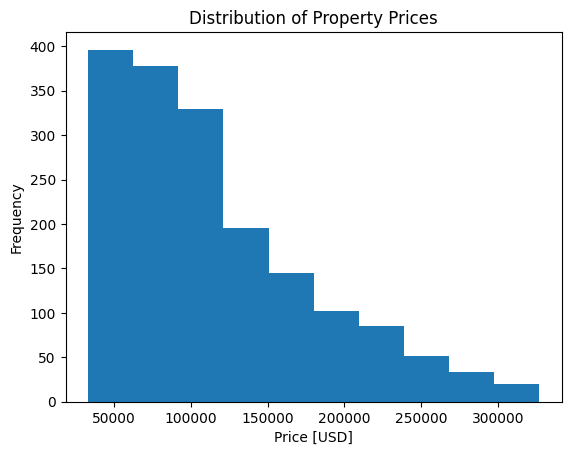

In [29]:
# Let's visualize the distribution of property prices
#import matplot
import matplotlib.pyplot as plt

#create histogram for price
fig, ax = plt.subplots()

#create a histogram for price_usd
ax.hist(df["price_usd"])

#create x & y labels axis and title  label
ax.set_xlabel("Price [USD]")
ax.set_ylabel("Frequency")
ax.set_title("Distribution of Property Prices");






In [30]:
# The distribution is strongly right-skewed (positively skewed). The tallest bars are on the left — most properties are priced between 
# 30,000 and 130,000. The distribution then tapers off slowly to the right, with a long thin tail of expensive properties extending to 300,000+.

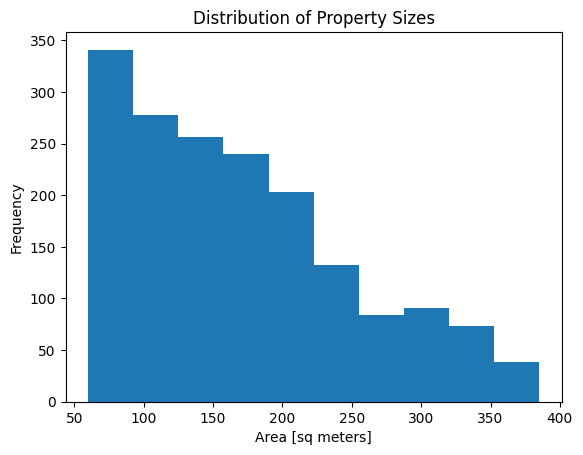

In [31]:
# Let's visualize the distribution of property sizes
#create a histogram for area
fig, ax = plt.subplots()

#create  histogram for area_m2
ax.hist(df["area_m2"])

#create x & y axis label and title label
ax.set_xlabel("Area [sq meters]")
ax.set_ylabel("Frequency")
ax.set_title("Distribution of Property Sizes");



In [32]:
# Also right-skewed, but for a different reason. Most properties in the dataset are apartments or smaller houses (50–150 m²),
# with a long tail of larger properties (mansions or commercial listings that crept into the dataset).
# Both price and area have a physical lower bound (a property must have positive size and a positive price) but no mathematical upper bound.
# Any variable with a hard floor but no ceiling tends to be right-skewed.

#What this means for size-price analysis: If we correlate raw area_m2 with raw price_usd, the handful of extreme outliers 
# (a 800 m² mansion at $300,000) will dominate the relationship and misrepresent the typical market.
# We will need to remove these before any scatterplot or correlation analysis 

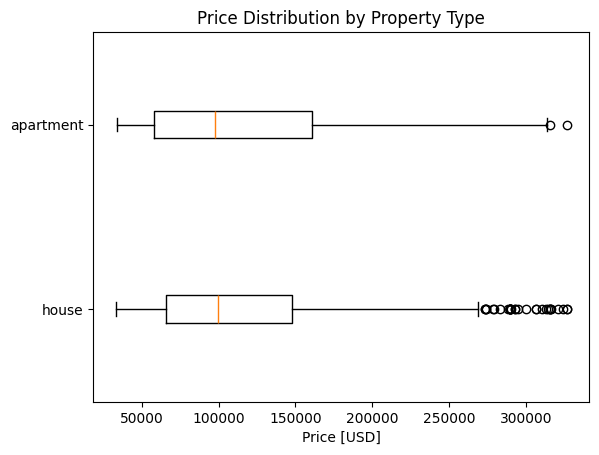

In [33]:
prop_types = df["property_type"].unique() #Get the unique category names on the column "property_type"

#Create a list of price arrays, one for each type
data_by_type = [df[df["property_type"] == label]["price_usd"] for label in prop_types]

fig, ax = plt.subplots() #PLOT

ax.boxplot(data_by_type, tick_labels= prop_types, vert=False)

ax.set_xlabel("Price [USD]")

ax.set_title("Price Distribution by Property Type")


plt.show()




In [34]:
#Houses: Read the median line and the two box edges off the plot: they give the typical house price and the range covered
#by the middle 50% of listings. Notice the string of outlier dots on the right — expensive houses extending well past the upper fence. 
#These are the luxury single-family homes that drive the right skew we saw in the histogram.

In [35]:
#Apartments: The median line sits close to the one for houses, confirming that the typical price for both property types is similar.
#The outlier tail is smaller: fewer dots sit beyond the upper fence.

#Key insight: The similar medians might lead you to conclude that property type does not affect price. But this is misleading. 
# Houses and apartments have similar total prices, but apartments are smaller. I will compute price_per_m2 — price per square meter —
# and the story changes dramatically: apartments are significantly more valuable per unit area.

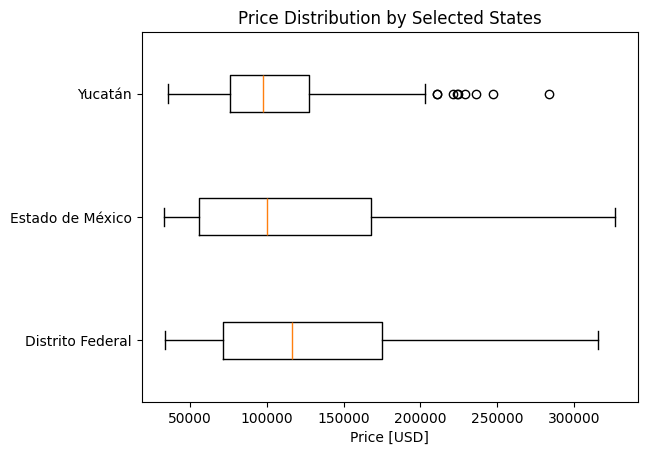

In [36]:
# Create a similar horizontal boxplot of "price_usd" by selected major states. Using the top 3 states by listing count.
#define selected states
selected_states = (
    df["state"]
    .value_counts()
    .head(3)
    .index.tolist()
) 

#prepare the data
data_by_state = [df[df["state"] == state]["price_usd"] for state in selected_states]

fig, ax = plt.subplots()

ax.boxplot(data_by_state, tick_labels = selected_states, vert =False) 

ax.set_xlabel("Price [USD]")
ax.set_title("Price Distribution by Selected States")
plt.show()

                 

In [37]:
# Reading the states boxplot — location as a price driver
#Distrito Federal:

# The highest median of the three — Mexico's capital commands a premium.
# A long right whisker: the ordinary market reaches well above the median, which is what you expect from a market running from 
# modest apartments to premium penthouses.

In [38]:
#Estado de México:

# A lower median than Distrito Federal but a comparable upper range — the long right whisker captures high-value suburban properties
# close to the capital.

In [39]:
#Yucatán:

#The lowest median and the narrowest box — the most affordable and the most consistent market. Most listings are similarly priced.
#A visible chain of outlier dots to the right — a distinct luxury segment (resort-style properties?) that lives well outside the main market

#Even without any formal statistics, the boxplot shows that location matters. Two properties with the same square footage —
#one in Distrito Federal, one in Yucatán — would likely sell at very different prices. This is the "location effect"

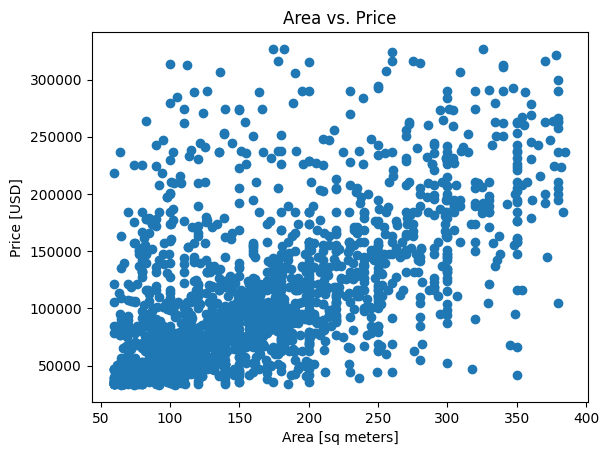

In [40]:
# The core of our research question is the relationship between size and price. Does a bigger property always cost more? 
# Is the relationship consistent, or does it vary by location?
#Scatterplot of area vs price:

fig, ax = plt.subplots() #plots for scatterplot

#Plot on the specific axes object
ax.scatter(x=df["area_m2"], y=df["price_usd"])

# x & y label axis, title label
ax.set_xlabel("Area [sq meters]")
ax.set_ylabel("Price [USD]")
ax.set_title("Area vs. Price")

plt.show()

In [41]:
#What we cannot tell from this plot:

#Whether the relationship is linear or curved (the compression hides it)
#How strong the relationship is (the main cluster is one indistinct blob)
#Whether the slope is consistent across different price ranges
# This is why quantile-based outlier removal is the next step — not to "cheat" the data, but to make the main market pattern visible.

Original: 1736 rows
Cleaned: 1365 rows
Removed: 371 rows


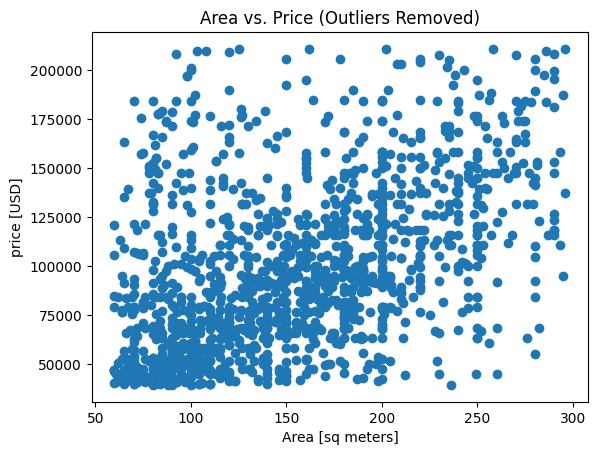

In [42]:
#Quantile-based outlier removal:

#define cutoff   percentages

lower_cut = 0.05  # Remove bottom 5%
upper_cut = 0.90  # Keep up to 90th percentile

# Filter the data

df_clean = (
    df[
        (df["price_usd"] > df["price_usd"].quantile(lower_cut)) &
        (df["price_usd"] < df["price_usd"].quantile(upper_cut)) &
        (df["area_m2"] < df["area_m2"].quantile(upper_cut)) # <-- Large area outliers also skew the scatter plot
        ]
)

# Show what changed
print(f"Original: {len(df)} rows")
print(f"Cleaned: {len(df_clean)} rows")
print(f"Removed: {len(df) - len(df_clean)} rows")


# Plot
fig, ax = plt.subplots()

ax.scatter(df_clean["area_m2"], df_clean["price_usd"])

ax.set_xlabel("Area [sq meters]")
ax.set_ylabel("price [USD]")
ax.set_title("Area vs. Price (Outliers Removed)")

plt.show()

In [43]:
# The scatterplot shows a positive relationship between property area and price, meaning that larger properties generally
# sell for higher prices. However, the points are widely spread, showing that other factors, such as location and property type,
# also influence house prices. After removing outliers, the main pattern becomes clearer, making it easier to understand 
# the relationship between area and price and prepare for further analysis.

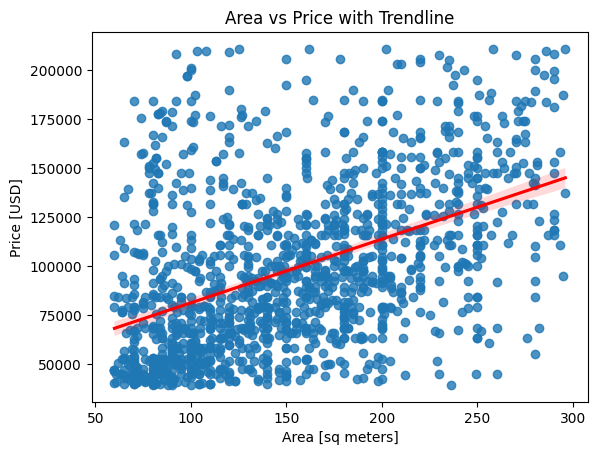

In [44]:
# Matplotlib's scatter shows the points; it does not fit a line. We need a regression line — the line of best fit that summarizes
# the average relationship between x and y. Seaborn makes this effortless with sns.regplot().

#import seaborn for visualizing trends
import seaborn as sns

# Create figure and axis explicitly
fig, ax =plt.subplots()

# Use Seaborn to plot scatter + trendline
sns.regplot(
    data = df_clean,
    x="area_m2",
    y="price_usd",
    line_kws={"color": "red"},
    ax = ax # Pass the axis to seaborn
)

ax.set_xlabel("Area [sq meters]")
ax.set_ylabel("Price [USD]")
ax.set_title("Area vs Price with Trendline")

plt.show()
              

In [45]:
# The red line (regression line): The line of best fit slopes upward — 
# confirming a positive relationship between area and price. As property size increases, price tends to increase.

# We have established that size affects price — the scatterplot shows a clear upward slope. But the strength of that relationship
# might vary dramatically by location. Does a 100 m² house cost the same in Distrito Federal as in Yucatán? And beyond price, 
# does the relationship between size and price follow the same pattern in different states?

# To answer this, we first need to understand which states have the highest prices — and then we can compare the size-price relationship
# across locations.

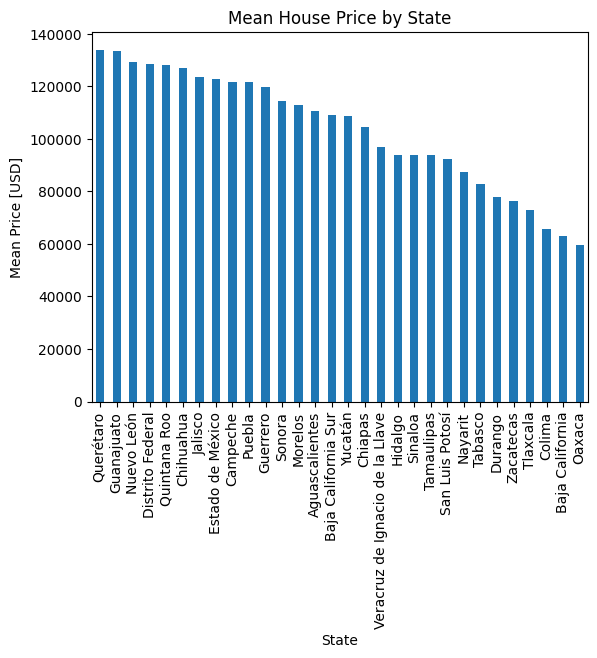

In [46]:
# # Aggregate data using groupby
mean_price_by_state = (
    df.groupby("state")["price_usd"]
    .mean()
    .sort_values(ascending = False)
)

# Create figure and axes explicitly
fig, ax = plt.subplots()

# Use pandas plot method with explicit axes
mean_price_by_state.plot(
    kind = "bar",
    ax = ax # pass the axes to pandas
)

ax.set_xlabel("State")
ax.set_ylabel("Mean Price [USD]")
ax.set_title("Mean House Price by State")

plt.show()

In [47]:
# Now we know which states are most expensive overall, let's examine whether the relationship between size and price is consistent across locations. 
# This is a fundamentally different question from "which state is expensive?" — it is asking "does size explain price equally well everywhere?"

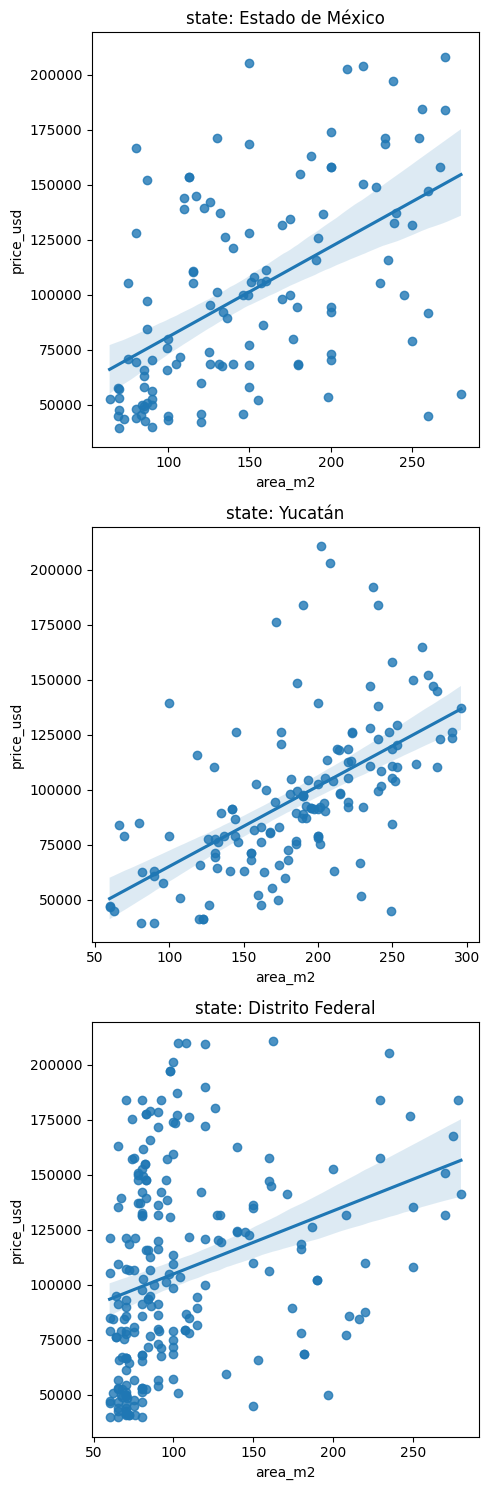

In [48]:
#create a custom figure & axes
fig, axes = plt.subplots(3, 1, figsize=(5, 15), sharey=True)

#create a list of the top 3 states
top_states = selected_states

# Filter df_clean to include only these states
df_states = df_clean[df_clean["state"].isin(top_states)]

#loop through states and plot on each axis
states = df_states["state"].unique()

for ax, state in zip(axes, states):
    #Filter data for the current state
    subset = df_states[df_states["state"]== state]

    # Use regplot (Axes-level) which accepts 'ax='
    sns.regplot(
        data = subset,
        x="area_m2",
        y="price_usd",
       # color='tab: blue',
        ax=ax
    )

    ax.set_title(f"state: {state}")

plt.tight_layout()
plt.show()


In [49]:
## how location changes the size-price relationship

# Estado de México — moderate positive relationship:
# The regression line rises at a clear angle — area does predict price here.
# Wide confidence band — the relationship is real but imprecise. Many properties deviate substantially from the line.
# Several high-price properties sit well above the line, suggesting other factors (proximity to Mexico City? Specific neighborhoods?) drive premiums.


#Yucatán — strongest and most consistent relationship:
# Narrow confidence band — the regression line is estimated with high precision. The relationship between size and price is more predictable here
 # than in the other two states.
# Points cluster more tightly around the line.
# Interpretation: in Yucatán, size is a stronger predictor of price than elsewhere.

# Distrito Federal — weakest relationship:

# Notice the compression on the x-axis — most properties cluster between 60–120 m². In Mexico City, land is expensive and apartments dominate,
# so large properties are genuinely rare.
# The regression line is nearly flat, and the confidence band is wide — size barely explains price in Distrito Federal.
# Interpretation: in Mexico City, price depends more on location within the city (neighborhood, floor, view, proximity to transit) than on raw size. A 100 m² apartment in Polanco is worth far more than a 100 m² apartment in the periphery.

In [50]:

data_path = "./mexico-real-estate-combined-clean.csv"

data = pd.read_csv(data_path)

print(f"Dimensions: {data.shape[0]} rows and {data.shape[1]} columns")
data.head()

Dimensions: 1736 rows and 6 columns


,property_type,state,lat,lon,area_m2,price_usd
0,house,Estado de México,19.560181,-99.233528,150.0,67965.56
1,house,Nuevo León,25.688436,-100.198807,186.0,63223.78
2,apartment,Guerrero,16.767704,-99.764383,82.0,84298.37
3,apartment,Guerrero,16.829782,-99.911012,150.0,94308.80
4,house,Yucatán,21.052583,-89.538639,205.0,105191.37


In [51]:
# since scatter plots above — one with a tight cluster around a rising line, one with a diffuse cloud that slopes upward —
# how can we put it in a number & which relationship is stronger?

# The Pearson correlation coefficient answers exactly this question.
# It converts the visual impression of a scatter plot into a single number between -1 and 1

In [52]:
# let's Calculate the National Area-Price Correlation using Pearson's method
corr_price_area =  (
    data["area_m2"]
    .corr(data["price_usd"])
)

print(f"The correlation between Area and Price is: {corr_price_area:.4f}")

The correlation between Area and Price is: 0.5855


In [53]:
# The correlation between area and price is 0.5855, indicating a moderate positive relationship: larger properties # 
# generally have higher prices. This suggests that area explains approximately 34% of the variation in property prices,
# while the remaining variation may be due to factors such as location, property type, and condition. However, 
# correlation does not prove causation, and further analysis is needed to understand how these factors influence property prices.

In [54]:
# Computing the full correlation matrix.

corr_matrix = (
    data
    .select_dtypes("number")
    .corr()
)

corr_matrix

,lat,lon,area_m2,price_usd
lat,1.000000,-0.480231,0.082314,-0.085868
lon,-0.480231,1.000000,0.095522,0.032815
area_m2,0.082314,0.095522,1.000000,0.585518
price_usd,-0.085868,0.032815,0.585518,1.000000


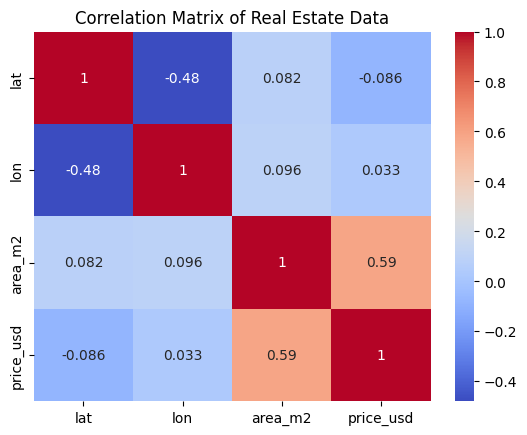

In [55]:
# heatmap encodes the correlation values as colors — making patterns immediately visible to the eye.

# create a figure
fig, ax = plt.subplots()

sns.heatmap(    #create the heatmap using seaborn
    corr_matrix,
    annot=True, # add the number to boxes
    cmap="coolwarm",
    ax=ax
)

ax.set_title("Correlation Matrix of Real Estate Data")

plt.show()

In [56]:
# The correlation heatmap shows that area and price have a moderate positive relationship (0.59), meaning larger properties 
# generally have higher prices. Latitude and longitude have weaker relationships with price, while their negative correlation
# of approximately -0.48 reflects Mexico’s geographical shape. Overall, the heatmap helps identify relationships between variables, 
# but further analysis is needed to understand how location and other factors affect property prices.

In [57]:
# Let's calculate correlations per state

correlations_by_state = (
    data
    .groupby("state")
    [["area_m2", "price_usd"]]
    .corr()       # Build correlation matrix per state
    .iloc[:, 1]     # Keep only the price_usd column 
    .xs("area_m2", level=1)     # To extract one correlation per state
    .sort_values(ascending=False)   # To rank states from strongest to weakest area-price correlation
    #.head()    #to check the first 5 rows
)

print(correlations_by_state.head(5))
print("\n... and the bottom 5 ...\n")
print(correlations_by_state.tail(5))

state
Zacatecas              1.000000
Colima                 0.988235
Sonora                 0.911524
Durango                0.909258
Baja California Sur    0.880583
Name: price_usd, dtype: float64

... and the bottom 5 ...

state
Nuevo León                         0.578696
Veracruz de Ignacio de la Llave    0.567469
Distrito Federal                   0.410704
Tabasco                            0.241284
Oaxaca                            -1.000000
Name: price_usd, dtype: float64


In [58]:
# The results show that the relationship between property area and price varies across Mexican states. In some states, 
# area strongly predicts price, while in others, factors such as location and amenities may have a greater influence. 
# This means the national correlation of 0.59 does not represent every state accurately, so we should consider each state’s
# sample size and analyse the markets separately.

In [59]:
# # Calculate correlation by property_type
correlations_by_prop = (
    data
    .groupby("property_type")
    [["area_m2", "price_usd"]]
    .corr()
    .iloc[:, 1] 
    .xs("area_m2", level=1)
)

print(correlations_by_prop)

property_type
apartment    0.519021
house        0.719280
Name: price_usd, dtype: float64


In [60]:
# The results show that houses have a stronger positive correlation (r ≈ 0.72) between area and price than apartments (r ≈ 0.52).
# This means that size is a more reliable predictor of house prices, while apartment prices are also influenced by factors such as location, 
# floor level, and building amenities. Therefore, property size matters for both types, but other factors may have a greater influence 
# on apartment prices.

In [61]:
# lets create a column for price_per_square

df = (
    data
    .assign(price_per_m2 = lambda x: x["price_usd"] / x["area_m2"])

    )
df.head()

,property_type,state,lat,lon,area_m2,price_usd,price_per_m2
0,house,Estado de México,19.560181,-99.233528,150.0,67965.56,453.103733
1,house,Nuevo León,25.688436,-100.198807,186.0,63223.78,339.912796
2,apartment,Guerrero,16.767704,-99.764383,82.0,84298.37,1028.028902
3,apartment,Guerrero,16.829782,-99.911012,150.0,94308.80,628.725333
4,house,Yucatán,21.052583,-89.538639,205.0,105191.37,513.128634


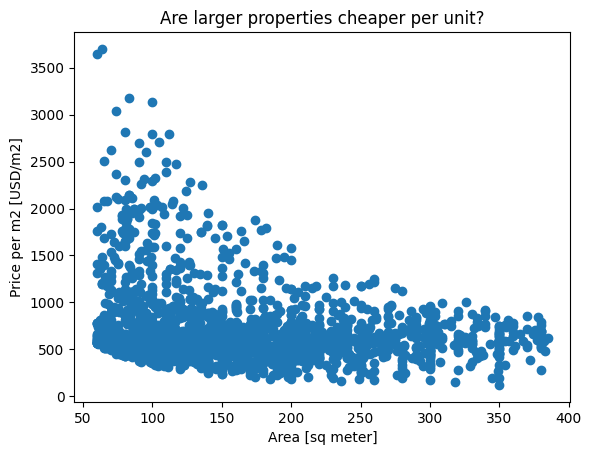

In [62]:
#  Scatterplot of area_m2 vs price_per_m2

fig, ax = plt.subplots()

# Scatter plot
ax.scatter(x=df["area_m2"], y=df["price_per_m2"])

ax.set_title("Are larger properties cheaper per unit?")
ax.set_xlabel("Area [sq meter]")
ax.set_ylabel("Price per m2 [USD/m2]")

plt.show()

In [63]:
# The scatterplot shows that smaller properties generally have a higher price per square metre than larger properties. 
# This may be because smaller properties are often in expensive city-centre locations, where amenities and location
# increase their value. The relationship is curved rather than straight, so Pearson correlation may not fully capture the pattern.

In [64]:
# Building the price_per_m2 feature to normalize prices by size. We saw that small apartments command higher prices per square meter
# than large houses — a hint that something beyond size is driving value. In this final lesson, we use price_per_m2 as our primary
# metric to isolate the location effect: the premium or discount that comes from where a property is located, independent of how big it is.

In [65]:
df["price_per_m2"].describe() # To check the statistic of the column

count    1736.000000
mean      733.446495
std       429.350784
min       120.300752
25%       489.318571
50%       614.035088
75%       806.417259
max      3700.657895
Name: price_per_m2, dtype: float64

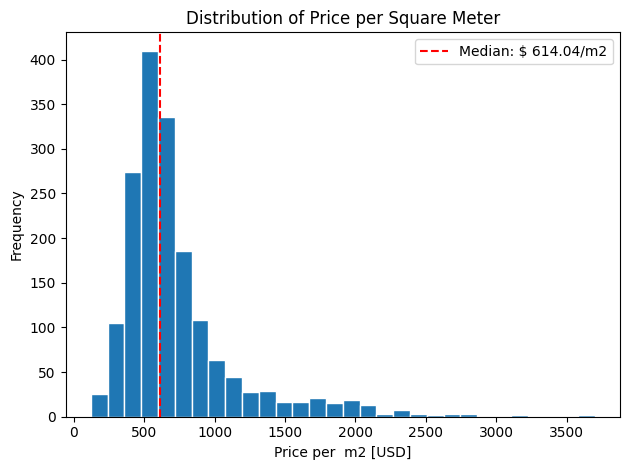

In [66]:
# Create a figure and axes
fig, ax = plt.subplots()

#create  a histogram with 30 bins
ax.hist(df["price_per_m2"], bins=30, edgecolor="white")

#set and label the axis
ax.set_title("Distribution of Price per Square Meter")
ax.set_xlabel("Price per  m2 [USD]")
ax.set_ylabel("Frequency")

# Add a vertical line for the median
median_price_per_m2 =  df["price_per_m2"].median()
ax.axvline(median_price_per_m2, color='red', linestyle='--',
           label=f'Median: ${median_price_per_m2: .2f}/m2')

ax.legend()

plt.tight_layout()
plt.show()


In [67]:
# The `price_per_m2` distribution is right-skewed, meaning most properties have a lower price per square metre, 
# while a few luxury properties have much higher prices. This is mainly due to expensive locations and high-value properties.
#Therefore, the median is a better measure of the typical price per square metre than the mean, because it is less affected by extreme values.

In [68]:
#calculate statistics by state

state_price_stats = (
    df
    .groupby("state")
    ["price_per_m2"]
    .agg(['mean', 'median', 'std'])
    .sort_values(by='median', ascending=False)

    .round(2)
)

print("Price per m2 Statistics by State:")   

state_price_stats

Price per m2 Statistics by State:


,mean,median,std
state,,,
Distrito Federal,1175.89,958.89,651.13
Guerrero,761.56,715.03,270.52
Quintana Roo,736.46,707.91,265.71
Oaxaca,683.02,683.02,196.87
Estado de México,763.75,674.30,396.69
Campeche,601.29,654.74,157.02
Nayarit,599.29,651.38,196.19
Querétaro,687.23,644.17,230.29
Jalisco,743.57,641.55,370.42


In [69]:
#  The results show that states with higher median prices per square metre are often expensive urban or tourist areas,
# while rural states tend to have lower prices. The standard deviation shows how much property prices vary within each state.
# The median is the best measure of typical property prices because it is less affected by a few extremely expensive properties.

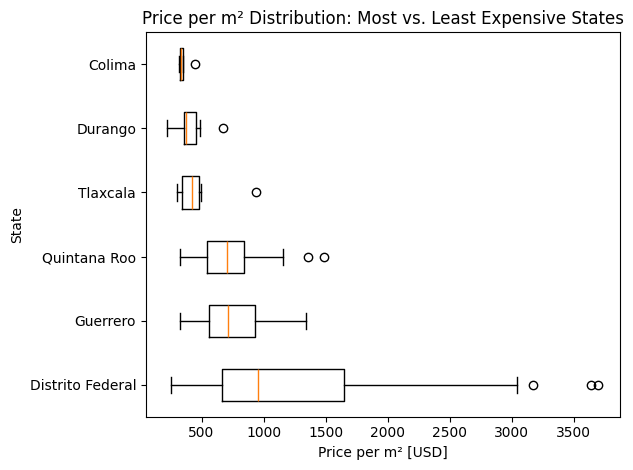

In [70]:
# Identify the states we want to plot (Top 3 and Bottom 3)
top_states = state_price_stats.head(3).index.tolist()
bottom_states = state_price_stats.tail(3).index.to_list()
target_states = top_states + bottom_states

# Filter the data through target_states
df_states = df[df["state"].isin(target_states)]

# Prepare the data for plotting & creating list of arrays, one for each state in our target list
data_to_plot = [df_states[df_states["state"] == state]["price_per_m2"]
                for state in target_states]

# Let's plot
fig, ax = plt.subplots()

ax.boxplot(data_to_plot, tick_labels=target_states, vert=False)
ax.set_title("Price per m² Distribution: Most vs. Least Expensive States")
ax.set_xlabel("Price per m² [USD]")
ax.set_ylabel("State")

plt.tight_layout()
plt.show()

In [71]:
# The boxplot shows that location has a major effect on property prices. Expensive states, such as Distrito Federal, 
# have higher prices per square metre and greater price variation, while cheaper states tend to have lower and more 
# consistent prices. However, sample sizes should be checked, as states with very few listings may not provide reliable results.

In [72]:
# Boxplots show the location effect visually. Now let's quantify it: what fraction of the total variation in price_usd comes
# from between-state differences vs within-state differences?

# Let's check if between-state variance >> within-state variance, then knowing which state a property is in explains more of
# its price than any within-state factor (like size). This directly answers our research question.

In [ ]:
# Correlation between size and price
size_price_correlation = df[["area_m2", "price_usd"]].corr().iloc[0, 1]
print(f"Correlation between area and price: {size_price_correlation:.2f}")

# Calculate the variance components
# Total variance in price_usd
total_variance = df["price_usd"].var()

# Between state variance (variance of the state means)
state_means = df.groupby("state")["price_usd"].mean()
between_variance = state_means.var()

# Within-state variance
within_variance = df.groupby("state")["price_usd"].var().mean()

# calculate the percentage
between_pct = (between_variance / total_variance) * 100
within_pct = (within_variance / total_variance) * 100

print(f"\nVariance Decomposition:")
print(f"  Between-state variance: {between_pct:.1f}%")
print(f"  Within-state variance: {within_pct:.1f}%")
print(f"  Ratio (Between/Within): {between_variance/within_variance:.2f}")


Correlation between area and price: 0.59

Variance Decomposition:
  Between-state variance: 11.8%
  Within-state variance: 11.8%
  Ratio (Between/Within): 0.15


In [74]:
# The variance decomposition helps determine whether property prices vary more between states or within each state. 
# If the between-state variance is greater than the within-state variance, location plays a major role in explaining 
# price differences. A ratio above 1 suggests that differences between states are greater, while a ratio below 1 suggests
# that differences within states are greater.

Price per m² by Property Type:
                  mean  median  count
property_type                        
apartment      1138.51  958.89    407
house           609.40  570.77   1329


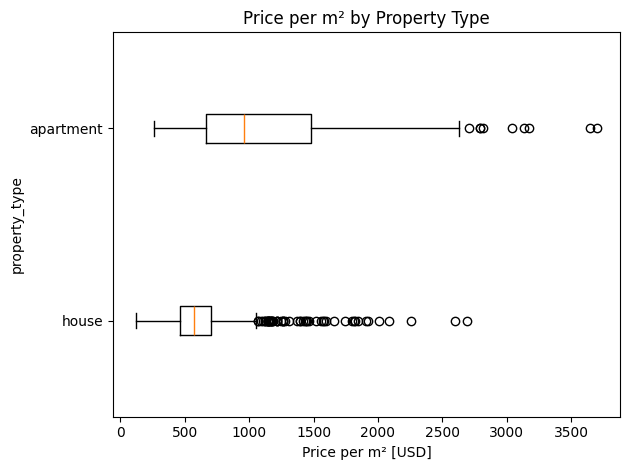

In [75]:
# Calculate summary statistics by property_type
property_type_stats = (
    df
    .groupby("property_type")
    ["price_per_m2"]
    .agg(['mean', 'median', 'count'])
    .round(2)

)

print("Price per m² by Property Type:")
print(property_type_stats)

# the unique property type
prop_types =df["property_type"].unique()

# prepare the list data
data_by_type = [df[df["property_type"] == p_type]["price_per_m2"]
                for p_type in prop_types]

# plot
fig, ax = plt.subplots()

ax.boxplot(data_by_type, tick_labels=prop_types, vert=False)
ax.set_title("Price per m² by Property Type")
ax.set_xlabel("Price per m² [USD]")
ax.set_ylabel("property_type")

plt.tight_layout()
plt.show()

In [76]:
# The boxplot shows that apartments generally have a higher median price per square metre than houses. 
# Apartments also have a wider spread of prices because their values depend heavily on location, amenities, and luxury features.
# Houses tend to have lower prices per square metre, although some expensive houses appear as outliers.

# This suggests that house prices are more closely related to size, while apartment prices may be more influenced by location and amenities.

In [77]:
# Group by both state and property_type
combined_stats = (
    df
    .groupby(["state", "property_type"])
    ["price_per_m2"]
    .agg(['median', 'count'])
    .round(2)

)

#  Filter for groups with at least 5 properties
combined_stats_filtered = combined_stats[combined_stats['count'] >= 5]

# Sort by median price per m²
combined_stats_filtered  = combined_stats_filtered.sort_values(
    by='median', ascending=False
)

print("Top 15 State-Property Type Combinations:")
display(combined_stats_filtered.head(15))

print("\nBottom 10 State-Property Type Combinations:")
combined_stats_filtered.tail(10)

Top 15 State-Property Type Combinations:


,,median,count
state,property_type,,
Nuevo León,apartment,1424.90,12
Jalisco,apartment,1288.66,8
Distrito Federal,apartment,1140.09,214
Quintana Roo,apartment,1003.79,11
Querétaro,apartment,1003.41,12
Estado de México,apartment,969.18,27
Puebla,apartment,960.88,22
Veracruz de Ignacio de la Llave,apartment,818.62,10
Yucatán,apartment,799.68,21



Bottom 10 State-Property Type Combinations:


,,median,count
state,property_type,,
Hidalgo,house,526.86,17
San Luis Potosí,house,493.82,45
Sonora,house,486.06,12
Sinaloa,house,482.46,23
Yucatán,house,481.21,150
Veracruz de Ignacio de la Llave,house,474.18,107
Aguascalientes,house,436.44,10
Tlaxcala,house,424.56,6
Durango,house,372.30,6


In [78]:
# The two-way table compares median price per square metre by state and property type. Apartments and houses in
#Distrito Federal are  likely to have higher prices, while houses in rural states may have lower prices per square metre.
# Both location and property type affect prices, but location appears to have the greater influence in the Mexican housing market.

# The `count >= 5` filter ensures that each state and property-type group contains at least five properties. 
# This makes the median more reliable and reduces the risk of drawing conclusions from very small, unrepresentative samples.
    

In [79]:
# The analysis shows that both size and location affect property prices, but location appears to be the stronger 
# factor in determining price per square metre. Property prices are right-skewed, and although larger properties generally 
# cost more, size alone cannot explain all price differences. Prices also vary considerably between Mexican states, 
# suggesting that location has a major influence on property value.

# Overall, knowing which state a property is in may provide more useful information about its price per square metre than knowing its size alone. 
# However, this conclusion should be supported by the variance decomposition results, and the analysis shows association rather than proving causation.